In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd .read_csv('creditcard.csv')

In [7]:
print(df.shape)

(284807, 31)


In [8]:
print(df.head())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [9]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [11]:
print(df['Class'].value_counts())
print(f"\nFraud percentage: {df['Class'].mean() * 100:.4f}%")

Class
0    284315
1       492
Name: count, dtype: int64

Fraud percentage: 0.1727%


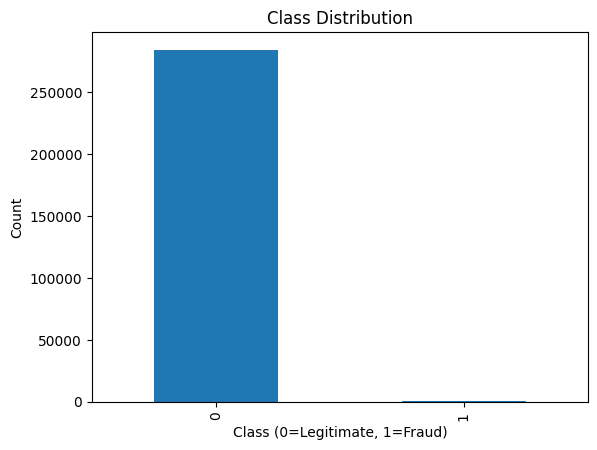

In [12]:
df['Class'].value_counts().plot(kind='bar')
plt.title("Class Distribution")
plt.xlabel("Class (0=Legitimate, 1=Fraud)")
plt.ylabel("Count")
plt.show()

Exactly — 0.17% fraud. That means out of every 10,000 transactions, only 17 are fraudulent.

This is called class imbalance — and it's the central challenge of fraud detection.

Here's why it's a problem:

If your model just predicts "legitimate" for every single transaction — never predicts fraud at all — it would be 99.83% accurate. Sounds great, but it's completely useless. It would miss every single fraud case.

This is why accuracy is a misleading metric for imbalanced datasets. You need better metrics.

The metrics that actually matter for fraud detection:

Precision — of all transactions I flagged as fraud, how many were actually fraud? (avoiding false alarms)

Recall — of all actual frauds, how many did I catch? (catching real fraud)

F1 Score — balance between precision and recall

ROC-AUC — overall model discrimination ability

In fraud detection, recall is usually more important — missing a real fraud (false negative) is worse than a false alarm (false positive).

In [13]:
from sklearn.model_selection import train_test_split

X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")
print(f"Training fraud cases: {y_train.sum()}")
print(f"Test fraud cases: {y_test.sum()}")

Training set: (227845, 30)
Test set: (56962, 30)
Training fraud cases: 394
Test fraud cases: 98


Here, axis = 1 implies - drop a column and if axis = 0 drop the row 

test_size = 0.2 means to split data into 80% training, 20% testing.

Training set — model learns from this

Test set — model never sees this during training, used only to evaluate real-world performance

random_state=42

The split is random — but random_state fixes that randomness so you get the same split every time you run the code.

Without it: every run gives a different split, results change, hard to reproduce.
With it: same split every time, results are reproducible.

42 is just a convention — any number works.


stratify=y

This is critical for imbalanced datasets.

Without stratify: random split might put most fraud cases in training and very few in test — or vice versa. Test set wouldn't represent real distribution.

With stratify=y: ensures both training and test sets maintain the same fraud ratio (0.17%) as the original dataset. Both sets are representative.

For imbalanced data like fraud detection — always use stratify.

Perfect split — 80/20, and fraud cases are proportionally distributed (394 train, 98 test).

Now let's handle the class imbalance. We'll use a technique called SMOTE — Synthetic Minority Oversampling Technique.

What SMOTE does:

Instead of just duplicating fraud cases (which doesn't add new information), SMOTE creates synthetic fraud cases by interpolating between existing fraud cases. It looks at real fraud transactions, finds similar ones, and generates new ones in between.

Result: balanced dataset where model sees enough fraud examples to learn the pattern.

SMOTE will create synthetic fraud cases to balance the dataset.

from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

print(f"Before SMOTE - Fraud: {y_train.sum()}, Legitimate: {(y_train==0).sum()}")
print(f"After SMOTE - Fraud: {y_train_balanced.sum()}, Legitimate: {(y_train_balanced==0).sum()}")

SMOTE created 227,057 synthetic fraud transactions (227,451 - 394) by interpolating between the 394 real fraud cases. Model now has equal exposure to both classes during training.

Now let's scale the features — remember standardization from week 1? Amount and Time have very different scales than V1-V28, which are already PCA transformed. We need everything on the same scale:

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_balanced)
X_test_scaled = scaler.transform(X_test)

Notice two different calls:

fit_transform on training data — learns mean/std from training, then scales

transform only on test data — uses the same mean/std learned from training

Why do we use fit_transform on training data but only transform on test data?


**The rule: test data must be treated as if it's unseen future data.**

In real world: your model is trained today, deployed tomorrow. Tomorrow's transactions are new — you don't know their mean or std in advance.

So when scaling:

**Training data — `fit_transform`:**
- `fit` — learns mean and std from training data
- `transform` — scales training data using those values

**Test data — `transform` only:**
- Uses the SAME mean and std learned from training
- Does NOT learn new mean/std from test data

**Why not fit on test data too?**

If you fit on test data, you're letting future information leak into your model evaluation. The test set would be scaled differently than real future data would be. Your evaluation becomes unreliable — model looks better than it actually is in production.

This is called **data leakage** — one of the most common and costly mistakes in ML. Models that look great in testing but fail in production often have data leakage.

**Simple analogy:**

You're a teacher standardizing exam scores. You calculate the class average from students who already took the exam (training). When next year's students take the exam, you use last year's average to standardize their scores — not recalculate a new average from them.

Always fit on training, transform on test. Never the other way around.


### Proper Exploratory Data Analysis (EDA)

In [16]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


Amount column is heavily skewed:

Mean = 88 but median (50%) = 22 — mean is much higher than median

Std = 250 — huge spread

Max = 25,691 — extreme outlier pulling the mean up

When mean >> median, it signals right skew — most transactions are small amounts but a few very large transactions are pulling the average up.

Why this matters for ML:
That max of 25,691 vs median of 22 is a massive range. Without scaling, the Amount feature would dominate the model unfairly — we already handled this with StandardScaler.

Lets visualize it:

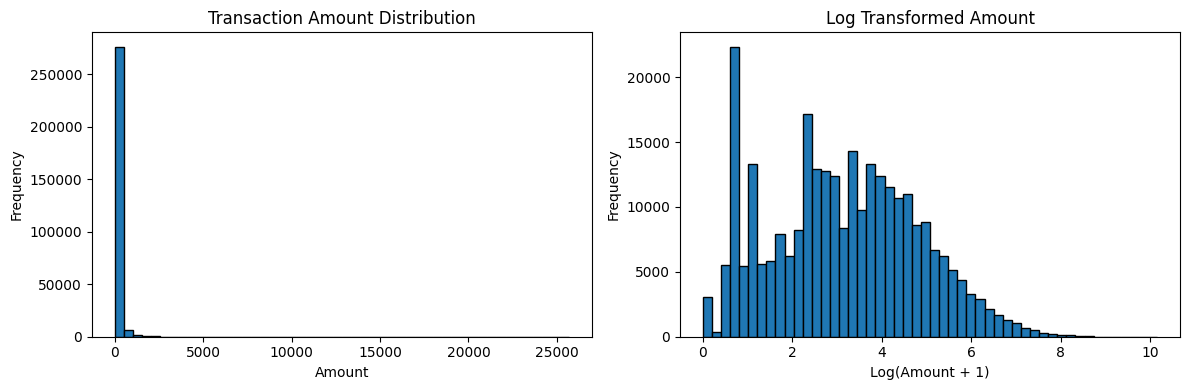

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Amount distribution
axes[0].hist(df['Amount'], bins=50, edgecolor='black')
axes[0].set_title('Transaction Amount Distribution')
axes[0].set_xlabel('Amount')
axes[0].set_ylabel('Frequency')

# Log transformed amount
axes[1].hist(np.log1p(df['Amount']), bins=50, edgecolor='black')
axes[1].set_title('Log Transformed Amount')
axes[1].set_xlabel('Log(Amount + 1)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

What happened:

First plot — raw Amount. Almost all transactions clustered near zero, one extremely long tail to the right (those large transactions). Completely dominated by outliers, hard to see the actual distribution.

Second plot — log transformed Amount. Spreads the data out, compresses the extreme values, reveals the actual underlying distribution. Much closer to normal.

Why log transformation helps ML models:

Reduces outlier impact — 25,691 becomes log(25,692) = 10.1, much less extreme
Many ML algorithms assume roughly normal distributions
Gradients behave better during training when features are well distributed


Now let's check outliers formally using the IQR method you remembered yesterday:

In [20]:
Q1 = df['Amount'].quantile(0.25)
Q3 = df['Amount'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['Amount'] < lower_bound) | (df['Amount'] > upper_bound)]
print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
print(f"Lower bound: {lower_bound:.2f}")
print(f"Upper bound: {upper_bound:.2f}")
print(f"Number of outliers: {len(outliers)}")
print(f"Outlier percentage: {len(outliers)/len(df)*100:.2f}%")

Q1: 5.6, Q3: 77.16499999999999, IQR: 71.565
Lower bound: -101.75
Upper bound: 184.51
Number of outliers: 31904
Outlier percentage: 11.20%


IQR — Interquartile Range:

It measures the spread of the middle 50% of your data.

Remember the quartiles from df.describe():

Q1 (25th percentile) = 5 — 25% of transactions are below this
Q2 (50th percentile) = 22 — median
Q3 (75th percentile) = 77 — 75% of transactions are below this

IQR = Q3 - Q1 = 77 - 5 = 72

That's the range covering the middle 50% of transactions.

The 1.5 × IQR rule:

Any value beyond this range is considered an outlier:

Lower bound = Q1 - 1.5 × IQR = 5 - 108 = -103 (impossible for amounts, so effectively no lower outliers)
Upper bound = Q3 + 1.5 × IQR = 77 + 108 = 185

So any transaction above $185 is flagged as an outlier by this rule.

Given max is $25,691  and upper bound is just $185 — yes, expect a large number of outliers. Transactions between $185 and $25,691 all get flagged.

Total outliers = 31904

Should we remove these outliers?

In most datasets — yes, remove outliers. But fraud detection is different:

Fraudulent transactions often ARE the outliers — unusually large amounts, unusual patterns. If we remove outliers, we might be removing actual fraud cases, which defeats the entire purpose.

Let's verify this intuition:

In [21]:
# How many of the outliers are actually fraud?
fraud_in_outliers = outliers['Class'].sum()
total_fraud = df['Class'].sum()

print(f"Total outliers: {len(outliers)}")
print(f"Fraud cases in outliers: {fraud_in_outliers}")
print(f"Total fraud cases: {total_fraud}")
print(f"Percentage of fraud in outliers: {fraud_in_outliers/total_fraud*100:.2f}%")

Total outliers: 31904
Fraud cases in outliers: 91
Total fraud cases: 492
Percentage of fraud in outliers: 18.50%


What this tells us:

18.5% of all fraud cases live in the outlier zone. If we had blindly removed outliers, we'd have lost 91 real fraud cases from our training data — making the model worse at catching exactly the transactions it needs to catch.

Decision: keep the outliers, use log transformation instead.

Instead of removing, we'll apply log transformation to Amount which we already visualized — this reduces outlier impact without losing the data.

Let's now look at correlations — which features are most related to fraud:

In [22]:
# Correlation with fraud
correlations = df.corr()['Class'].sort_values(ascending=False)
print("Top 10 features correlated with fraud:")
print(correlations.head(10))
print("\nBottom 10 features correlated with fraud:")
print(correlations.tail(10))

Top 10 features correlated with fraud:
Class    1.000000
V11      0.154876
V4       0.133447
V2       0.091289
V21      0.040413
V19      0.034783
V20      0.020090
V8       0.019875
V27      0.017580
V28      0.009536
Name: Class, dtype: float64

Bottom 10 features correlated with fraud:
V9    -0.097733
V1    -0.101347
V18   -0.111485
V7    -0.187257
V3    -0.192961
V16   -0.196539
V10   -0.216883
V12   -0.260593
V14   -0.302544
V17   -0.326481
Name: Class, dtype: float64


Positive correlation (top features):

V11 (0.154), V4 (0.133) — when these values are higher, fraud is more likely

Negative correlation (bottom features):

V17 (-0.326), V14 (-0.303), V12 (-0.261) — when these values are lower, fraud is more likely

V14 and V17 are your strongest predictors — most correlated with fraud (negative correlation still means strong relationship, just inverse).

Notice Amount isn't in either list — transaction amount alone isn't a strong fraud signal. Fraudsters are smart — they don't always make large transactions.

Visualise top predictors:

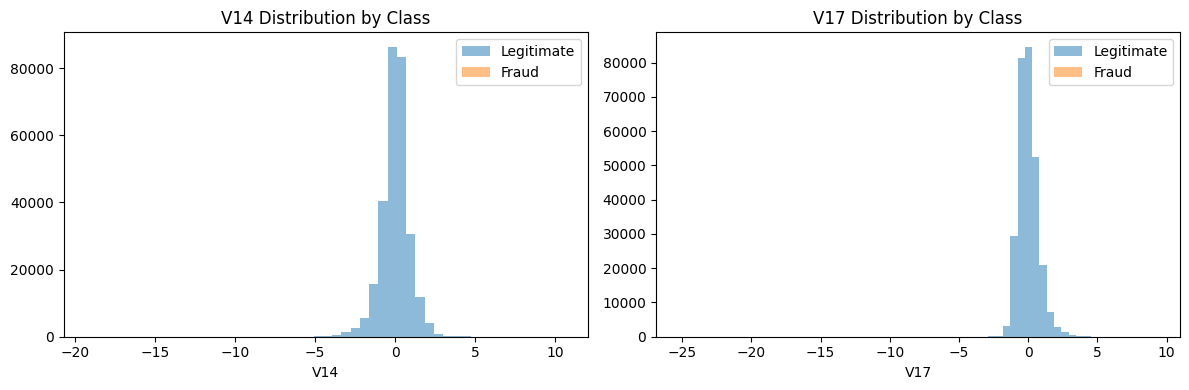

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# V14 distribution by class
axes[0].hist(df[df['Class']==0]['V14'], bins=50, alpha=0.5, label='Legitimate')
axes[0].hist(df[df['Class']==1]['V14'], bins=50, alpha=0.5, label='Fraud')
axes[0].set_title('V14 Distribution by Class')
axes[0].set_xlabel('V14')
axes[0].legend()

# V17 distribution by class
axes[1].hist(df[df['Class']==0]['V17'], bins=50, alpha=0.5, label='Legitimate')
axes[1].hist(df[df['Class']==1]['V17'], bins=50, alpha=0.5, label='Fraud')
axes[1].set_title('V17 Distribution by Class')
axes[1].set_xlabel('V17')
axes[1].legend()

plt.tight_layout()
plt.show()

The fraud (orange) is barely visible because there are so few fraud cases compared to legitimate — classic imbalance problem visually.

But look carefully at V14 — legitimate transactions cluster tightly around 0, while fraud cases spread further left (negative values). That separation, even if hard to see here, is what the model will learn from.

The scale issue makes fraud invisible on this chart. Let's fix that by plotting only the fraud distribution separately:

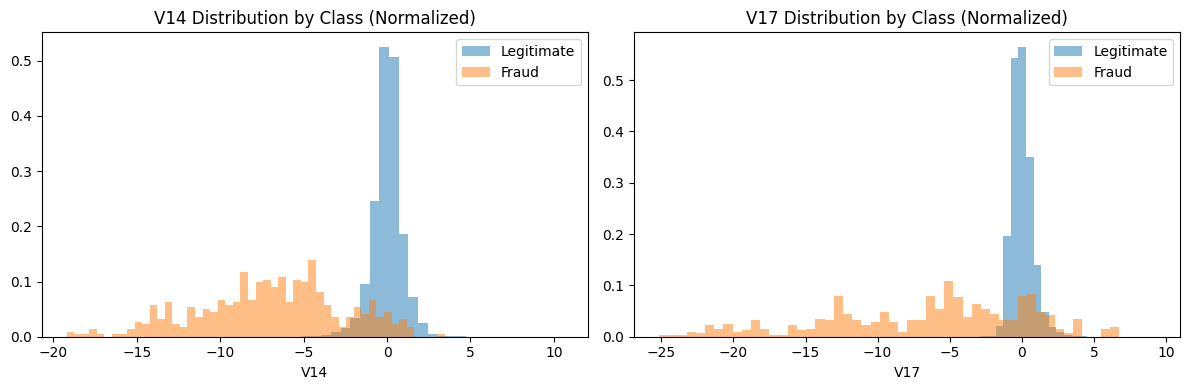

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# V14
axes[0].hist(df[df['Class']==0]['V14'], bins=50, alpha=0.5, label='Legitimate', density=True)
axes[0].hist(df[df['Class']==1]['V14'], bins=50, alpha=0.5, label='Fraud', density=True)
axes[0].set_title('V14 Distribution by Class (Normalized)')
axes[0].set_xlabel('V14')
axes[0].legend()

# V17
axes[1].hist(df[df['Class']==0]['V17'], bins=50, alpha=0.5, label='Legitimate', density=True)
axes[1].hist(df[df['Class']==1]['V17'], bins=50, alpha=0.5, label='Fraud', density=True)
axes[1].set_title('V17 Distribution by Class (Normalized)')
axes[1].set_xlabel('V17')
axes[1].legend()

plt.tight_layout()
plt.show()

density=True normalizes both distributions to the same scale so fraud is visible.

EDA is now complete. Here's what you found:

✅ 0.17% fraud — severe class imbalance

✅ Amount is heavily right skewed — log transformation needed

✅ 11.2% outliers in Amount — kept them because fraud cases live there

✅ V14 and V17 are strongest predictors

✅ Fraud transactions have distinctly different distributions

Lets build the Random Forest model to detect fraud

In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Train Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train_balanced)

print("Model trained successfully")
print(f"Number of trees: {rf_model.n_estimators}")

Model trained successfully
Number of trees: 100


n_estimators=100 means 100 decision trees will be built and combined.

That's the core idea of Random Forest — instead of one decision tree (which overfits easily), it builds many trees on random subsets of data and features, then takes a majority vote across all trees for the final prediction.

Think of it like asking 100 different experts instead of one — the collective decision is more reliable than any single expert.

More trees = more stable predictions but slower training
100 is a standard starting point

n_jobs=-1 means use all available CPU cores to train trees in parallel — speeds up training significantly.

Why Random Forest for fraud:

Handles imbalanced data well — even after SMOTE, it's robust

No feature scaling required — though we scaled anyway, trees don't actually need it

Handles non-linear patterns — fraud behavior isn't linear, trees capture complex patterns

Feature importance — tells you which features matter most, useful for explainability

Hard to overfit — averaging 100 trees reduces variance significantly

What a single decision tree does:

Imagine a flowchart:

Is V14 < -5? → likely fraud
Is Amount > 1000 AND V17 < -3? → likely fraud
Otherwise → legitimate

Random Forest builds 100 different versions of this flowchart, each trained on a random subset of data, then majority votes.

In [28]:
# Make predictions
y_pred = rf_model.predict(X_test_scaled)
y_pred_prob = rf_model.predict_proba(X_test_scaled)[:, 1]

# Evaluation metrics
print("Classification Report:")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_prob):.4f}")

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.83      0.83        98

    accuracy                           1.00     56962
   macro avg       0.91      0.91      0.91     56962
weighted avg       1.00      1.00      1.00     56962

ROC-AUC Score: 0.9644


For fraud (Class 1):

Precision: 0.83 — of all transactions flagged as fraud, 83% were actually fraud. 17% were false alarms.
Recall: 0.83 — of all actual fraud cases, we caught 83%. We missed 17%.
F1: 0.83 — balanced score between precision and recall
ROC-AUC: 0.9644 — model discriminates between fraud and legitimate extremely well

Overall accuracy: 100% — but remember, this is misleading due to class imbalance. The meaningful number is the fraud class metrics.

Is 83% recall good enough?

Depends on context:

Missing 17% of fraud means ~17 fraud cases per 10,000 slip through
In banking, you'd want recall higher — closer to 90%+
But precision matters too — too many false alarms and customers get frustrated with blocked legitimate transactions

This is called the precision-recall tradeoff — improving one often hurts the other.

ROC-AUC of 0.96 is genuinely strong — near perfect discrimination.

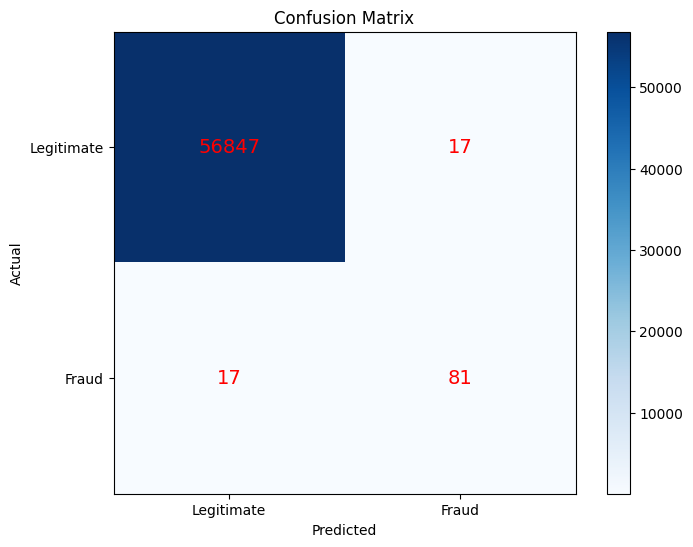

In [29]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()
plt.xticks([0, 1], ['Legitimate', 'Fraud'])
plt.yticks([0, 1], ['Legitimate', 'Fraud'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center', 
                color='red', fontsize=14)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Top left (56,847) — True Negatives:
Legitimate transactions correctly identified as legitimate. ✓

Top right (17) — False Positives:
Legitimate transactions incorrectly flagged as fraud. These are false alarms — real customers getting their card blocked unnecessarily.

Bottom left (17) — False Negatives:
Actual fraud cases the model missed. These slipped through undetected. ✗ Most costly mistake in fraud detection.

Bottom right (81) — True Positives:
Actual fraud cases correctly caught. ✓

In plain numbers:

Caught 81 out of 98 fraud cases — 83% recall
Missed 17 real fraud cases
Raised 17 false alarms on legitimate transactions

Interesting observation:
False positives and false negatives are both exactly 17 — pure coincidence, but it means the model is equally balanced between the two types of errors.


    Business interpretation:

Every missed fraud case (17) costs the bank the full transaction amount
Every false alarm (17) risks customer frustration and churn
81 caught fraud cases = real money saved

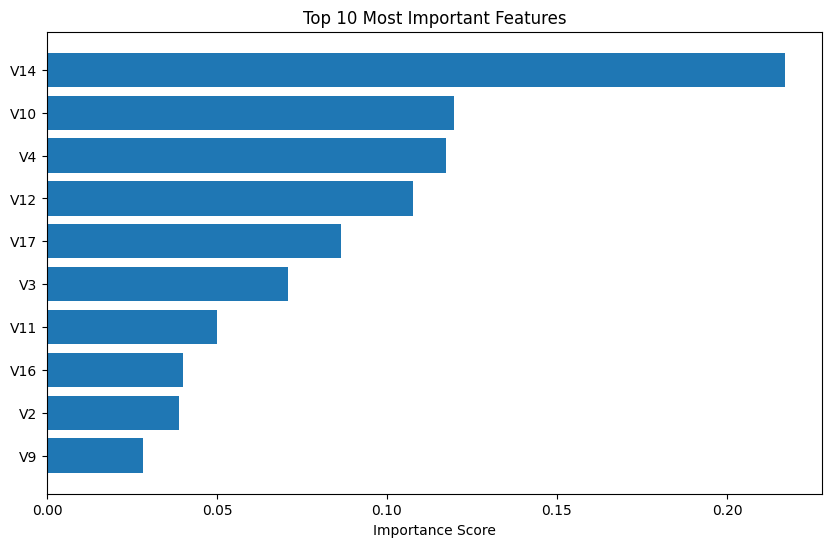

In [31]:
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
plt.barh(feature_importance['feature'], feature_importance['importance'])
plt.title('Top 10 Most Important Features')
plt.xlabel('Importance Score')
plt.gca().invert_yaxis()
plt.show()

V14 is dominant — importance score of 0.22, almost double the next feature V10. This perfectly confirms what EDA found through correlation analysis.

The full story this tells:

EDA found V14 had highest negative correlation with fraud (-0.30)

Random Forest independently found V14 most important (0.22 score)

Two different methods pointing to the same feature = strong signal

Your fraud detection project is now functionally complete:

✅ Loaded real dataset (284,807 transactions)
✅ Proper EDA — distributions, skewness, outliers, correlations
✅ Handled class imbalance with SMOTE
✅ Feature scaling with data leakage prevention
✅ Random Forest model trained
✅ Evaluated with proper metrics (precision, recall, F1, ROC-AUC)
✅ Confusion matrix analysis
✅ Feature importance visualization

In [33]:
import joblib

# Save model and scaler
joblib.dump(rf_model, 'fraud_detection_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

print("Model saved successfully")

Model saved successfully
